
# 02 — Potencial Solar e Geração Fotovoltaica

## Citizen Assist AI — Global Solution 2026.2

**Instituição:** FIAP  
**Componente curricular:** Soluções em Energias Renováveis e Sustentáveis  
**Projeto:** Citizen Assist AI  
**Etapa:** Análise do potencial solar fotovoltaico, eficiência energética e comparação de alternativas sustentáveis.  
**Localidade de referência:** São Paulo — SP, Brasil

---

### Objetivo

Investigar o potencial de geração de energia solar fotovoltaica para o cenário residencial definido na etapa anterior, utilizando dados de irradiação solar e parâmetros técnicos para estimar a capacidade de geração de um sistema fotovoltaico.

O estudo utilizará como referência o perfil de consumo residencial desenvolvido no Notebook 01, permitindo comparar a demanda energética estimada com o potencial de geração solar.

### Resultado esperado

Obter uma estimativa técnica de geração fotovoltaica, considerando as características de irradiação solar da região, a potência do sistema, os equipamentos utilizados e as perdas envolvidas no processo de conversão de energia.



## 2. Escopo e Metodologia

Esta etapa dará continuidade à análise de consumo residencial realizada no Notebook 01.

O estudo será desenvolvido em etapas:

1. Identificação e obtenção de dados de irradiação solar.
2. Definição da localidade utilizada como referência.
3. Importação, organização e validação dos dados.
4. Análise do comportamento da irradiação solar ao longo do ano.
5. Estimativa do potencial de geração fotovoltaica.
6. Dimensionamento preliminar do sistema.
7. Comparação entre a geração estimada e o consumo residencial.
8. Exportação dos resultados para utilização nas próximas etapas do Citizen Assist AI.

### Delimitação do estudo

O dimensionamento realizado neste notebook terá caráter estimativo.

Não serão considerados como conhecidos fatores específicos de uma instalação real, como orientação e inclinação exatas do telhado, sombreamento local, condições estruturais ou características elétricas de uma residência específica.

Esses fatores deverão ser identificados como limitações ou premissas quando não houver dados disponíveis.



## 3. Parâmetros Iniciais do Projeto

O dimensionamento fotovoltaico utilizará como referência o cenário residencial hipotético definido na primeira etapa do projeto.

### Características do cenário

- Localidade: São Paulo — SP.
- Perfil residencial: quatro moradores.
- Consumo mensal estimado: 150,40 kWh.
- Consumo anual estimado: 1.804,80 kWh.

Os valores representam um cenário simulado e não medições de uma residência real.


In [128]:

# Parâmetros gerais do projeto

# Localidade de referência
cidade = "São Paulo"
estado = "SP"
pais = "Brasil"

# Perfil residencial
quantidade_moradores = 4

# Consumo energético obtido no Notebook 01
consumo_mensal_kwh = 150.40
consumo_anual_kwh = consumo_mensal_kwh * 12

# Exibição dos parâmetros

print("PARÂMETROS DO PROJETO")
print("-" * 40)

print(f"Localidade: {cidade} - {estado}, {pais}")
print(f"Quantidade de moradores: {quantidade_moradores}")
print(f"Consumo mensal: {consumo_mensal_kwh:.2f} kWh")
print(f"Consumo anual: {consumo_anual_kwh:.2f} kWh")


PARÂMETROS DO PROJETO
----------------------------------------
Localidade: São Paulo - SP, Brasil
Quantidade de moradores: 4
Consumo mensal: 150.40 kWh
Consumo anual: 1804.80 kWh



## 4. Preparação do Ambiente

Nesta seção serão importadas as bibliotecas utilizadas no tratamento dos dados, nas operações matemáticas e na construção das visualizações.

O ambiente será organizado para facilitar a reprodução das análises e a manutenção do notebook.


In [129]:

# Importação das bibliotecas

import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configurações de visualização

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

# Configurações dos gráficos

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

print("Ambiente preparado com sucesso.")


Ambiente preparado com sucesso.



## 5. Fonte de Dados de Irradiação Solar

### Atlas Brasileiro de Energia Solar — 2ª Edição

A análise do potencial solar utilizará dados do Atlas Brasileiro de Energia Solar, desenvolvido pelo Laboratório de Modelagem e Estudos de Recursos Renováveis de Energia (LABREN), vinculado ao Instituto Nacional de Pesquisas Espaciais (INPE).

A base disponibiliza informações climatológicas de irradiação solar para diferentes localidades brasileiras, incluindo médias mensais e anuais.

### Características da fonte

- Instituição responsável: INPE / LABREN.
- Publicação: Atlas Brasileiro de Energia Solar — 2ª edição.
- Ano de referência: 2017.
- Localidade: São Paulo — SP.
- Abrangência: Estado de São Paulo, com dados distribuídos em uma grade espacial.
- Resolução espacial: 0,1° × 0,1° (aproximadamente 10 km).
- Formato de dados: CSV.
- Variável de interesse: irradiação no plano inclinado.
- Unidade original: Wh/m².dia.

### Justificativa

A utilização de dados de irradiação no plano inclinado permite estabelecer uma referência para estimar a energia solar incidente sobre uma superfície de módulos fotovoltaicos.

Os dados representam médias climatológicas e não previsões meteorológicas ou medições realizadas no telhado de uma residência específica.



### Limitações da fonte

Os dados do Atlas representam estimativas climatológicas obtidas a partir de informações de satélite e modelagem.

A resolução espacial da base não permite representar todas as particularidades de um imóvel individual. Além disso, a irradiação efetivamente recebida pelos módulos depende de fatores como orientação, inclinação, sombreamento e condições locais de instalação.

Portanto, os resultados deste estudo serão utilizados como referências para um dimensionamento preliminar, e não como garantia de geração energética.


In [130]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



## 6. Importação e Inspeção dos Dados

Nesta etapa será realizada a importação da base de irradiação solar obtida no Atlas Brasileiro de Energia Solar.

Inicialmente, serão verificadas as dimensões, as colunas, os tipos de dados e os primeiros registros do arquivo.

Essa inspeção permitirá identificar a organização da base antes de iniciar o tratamento e a seleção dos dados referentes ao município de São Paulo.

Referência: Irradiação do Plano Inclinado
Link: https://labren.ccst.inpe.br/atlas2_tables/SP_inc.html

In [131]:

# Caminho da base de irradiação solar

caminho_irradiacao = os.path.join(
    "dados",
    "tilted_latitude_means_SP.csv"
)

# Importação do arquivo CSV

df_irradiacao_original = pd.read_csv(
    caminho_irradiacao,
    sep=";",
    decimal=".",
    encoding="utf-8"
)

# Inspeção inicial

print("DIMENSÕES DA BASE")
print("-" * 40)

print(f"Linhas: {df_irradiacao_original.shape[0]}")
print(f"Colunas: {df_irradiacao_original.shape[1]}")

print("\nCOLUNAS DISPONÍVEIS")
display(
    pd.DataFrame({
        "coluna": df_irradiacao_original.columns,
        "tipo": df_irradiacao_original.dtypes.astype(str).values
    })
)

print("\nPRIMEIROS REGISTROS")
display(df_irradiacao_original.head())


DIMENSÕES DA BASE
----------------------------------------
Linhas: 2383
Colunas: 17

COLUNAS DISPONÍVEIS


,coluna,tipo
0,ID,int64
1,UF,object
2,LON,float64
3,LAT,float64
4,ANNUAL,int64
5,JAN,int64
6,FEB,int64
7,MAR,int64
8,APR,int64
9,MAY,int64



PRIMEIROS REGISTROS


,ID,UF,LON,LAT,ANNUAL,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC
0,4263,São Paulo,-48.15,-25.30,3928,4649,4775,4338,4077,3592,3204,3110,3720,3372,3461,4255,4587
1,4264,São Paulo,-48.05,-25.30,4148,4875,5059,4622,4344,3749,3310,3232,3859,3634,3739,4523,4833
2,4328,São Paulo,-48.15,-25.20,3840,4407,4616,4252,3963,3566,3229,3112,3732,3322,3399,4081,4398
3,4329,São Paulo,-48.05,-25.20,4045,4755,4916,4493,4206,3679,3318,3201,3876,3488,3596,4350,4660
4,4330,São Paulo,-47.95,-25.20,4147,4871,5054,4644,4347,3744,3316,3237,3828,3610,3743,4532,4835


In [132]:

# Verificação inicial da qualidade dos dados

print("VALORES AUSENTES POR COLUNA")
display(
    df_irradiacao_original.isna()
    .sum()
    .to_frame("valores_ausentes")
)

print("\nREGISTROS DUPLICADOS")
print(
    df_irradiacao_original.duplicated().sum()
)


VALORES AUSENTES POR COLUNA


,valores_ausentes
ID,0
UF,0
LON,0
LAT,0
ANNUAL,0
JAN,0
FEB,0
MAR,0
APR,0
MAY,0



REGISTROS DUPLICADOS
0



## 7. Seleção Geográfica da Área de Estudo

A base estadual contém diversos pontos geográficos distribuídos pelo território paulista.

Para esta análise, será selecionado o ponto de grade mais próximo de uma coordenada de referência da cidade de São Paulo.

A seleção será realizada utilizando latitude e longitude, considerando a distância geográfica entre os pontos.

Essa abordagem permite utilizar dados representativos da região de estudo sem presumir que a primeira linha da base corresponde à capital.


In [133]:

# Coordenadas aproximadas da região central de São Paulo
latitude_referencia = -23.5505
longitude_referencia = -46.6333

# Função para calcular distância geográfica pelo método Haversine
def calcular_distancia_km(lat1, lon1, lat2, lon2):
    raio_terra_km = 6371.0

    # Conversão individual para radianos
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    diferenca_lat = lat2 - lat1
    diferenca_lon = lon2 - lon1

    a = (
        np.sin(diferenca_lat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(diferenca_lon / 2) ** 2
    )

    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return raio_terra_km * c


# Cópia da base para seleção geográfica
df_irradiacao = df_irradiacao_original.copy()

# Cálculo da distância entre cada ponto e a referência
df_irradiacao["distancia_km"] = calcular_distancia_km(
    latitude_referencia,
    longitude_referencia,
    df_irradiacao["LAT"].to_numpy(),
    df_irradiacao["LON"].to_numpy()
)

# Ordenação dos pontos pela distância
df_irradiacao = df_irradiacao.sort_values(
    "distancia_km"
).reset_index(drop=True)

# Seleção do ponto mais próximo
ponto_irradiacao = df_irradiacao.iloc[0]

print("PONTO GEOGRÁFICO MAIS PRÓXIMO")
print("-" * 40)
print(f"ID: {ponto_irradiacao['ID']}")
print(f"Latitude: {ponto_irradiacao['LAT']}")
print(f"Longitude: {ponto_irradiacao['LON']}")
print(f"Distância da referência: {ponto_irradiacao['distancia_km']:.2f} km")



PONTO GEOGRÁFICO MAIS PRÓXIMO
----------------------------------------
ID: 5622
Latitude: -23.6005
Longitude: -46.649
Distância da referência: 5.79 km


In [134]:

# Visualização dos cinco pontos mais próximos

display(
    df_irradiacao[
        ["ID", "LAT", "LON", "distancia_km", "ANNUAL"]
    ].head(5)
)


,ID,LAT,LON,distancia_km,ANNUAL
0,5622,-23.60,-46.65,5.79,4658
1,5728,-23.50,-46.65,5.79,4671
2,5623,-23.60,-46.55,10.23,4641
3,5729,-23.50,-46.55,10.24,4659
4,5621,-23.60,-46.75,13.04,4701



## 8. Extração e Conversão da Irradiação Solar

Após a seleção do ponto geográfico mais próximo da região central de São Paulo, serão extraídos os valores mensais de irradiação solar.

Os dados disponibilizados pelo Atlas Brasileiro de Energia Solar representam médias diárias de irradiação para cada mês, expressas originalmente em Wh/m².dia.

Para facilitar os cálculos posteriores de geração fotovoltaica, os valores serão convertidos para kWh/m².dia, dividindo-se os resultados por 1.000.

Essa unidade também permite interpretar a irradiação diária como Horas de Sol Pleno (HSP), utilizada como referência em estimativas de geração de sistemas fotovoltaicos.


In [135]:

# Identificação das colunas correspondentes aos meses
colunas_meses = [
    "JAN", "FEB", "MAR", "APR", "MAY", "JUN",
    "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"
]

nomes_meses = [
    "Janeiro", "Fevereiro", "Março", "Abril",
    "Maio", "Junho", "Julho", "Agosto",
    "Setembro", "Outubro", "Novembro", "Dezembro"
]

# Extração dos dados do ponto geográfico selecionado
dados_mensais = pd.DataFrame({
    "mes": nomes_meses,
    "irradiacao_wh_m2_dia": [
        ponto_irradiacao[coluna]
        for coluna in colunas_meses
    ]
})

# Conversão de Wh/m².dia para kWh/m².dia
dados_mensais["irradiacao_kwh_m2_dia"] = (
    dados_mensais["irradiacao_wh_m2_dia"] / 1000
)

print("IRRADIAÇÃO SOLAR MENSAL — PONTO SELECIONADO")
print("-" * 55)
display(dados_mensais)

# Média anual diária informada pelo Atlas
irradiacao_media_anual = ponto_irradiacao["ANNUAL"] / 1000

print(
    f"Irradiação média anual diária: "
    f"{irradiacao_media_anual:.3f} kWh/m².dia"
)


IRRADIAÇÃO SOLAR MENSAL — PONTO SELECIONADO
-------------------------------------------------------


,mes,irradiacao_wh_m2_dia,irradiacao_kwh_m2_dia
0,Janeiro,4708,4.71
1,Fevereiro,5217,5.22
2,Março,4866,4.87
3,Abril,4734,4.73
4,Maio,4235,4.24
5,Junho,4090,4.09
6,Julho,4143,4.14
7,Agosto,5011,5.01
8,Setembro,4518,4.52
9,Outubro,4602,4.60


Irradiação média anual diária: 4.658 kWh/m².dia


### Visualização dos dados:

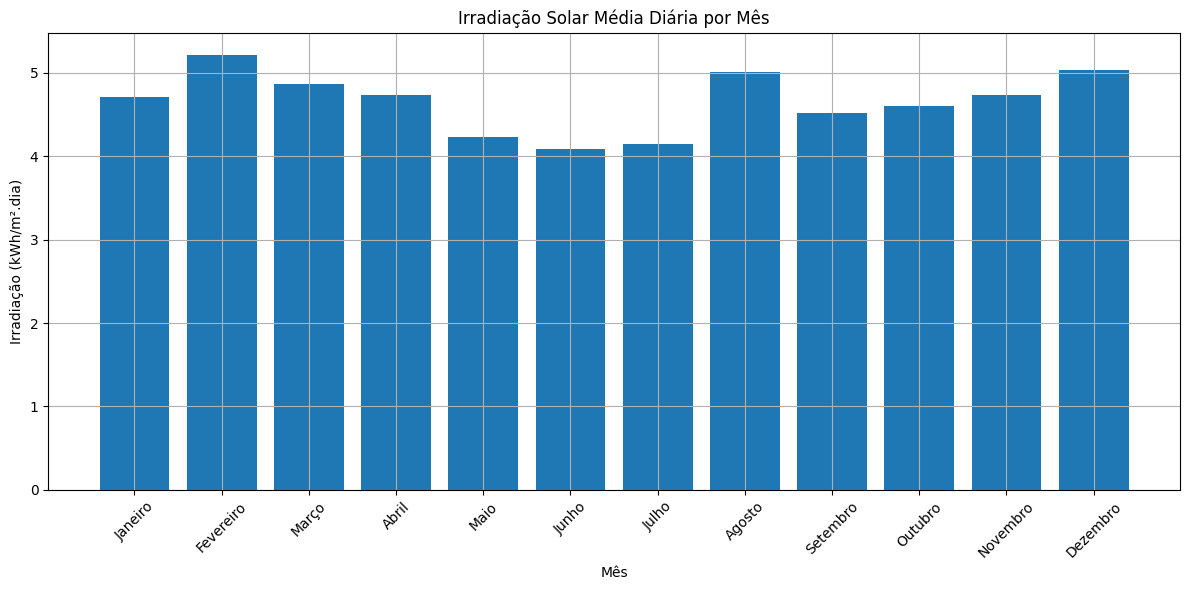

In [136]:

plt.figure()

plt.bar(
    dados_mensais["mes"],
    dados_mensais["irradiacao_kwh_m2_dia"]
)

plt.title("Irradiação Solar Média Diária por Mês")
plt.xlabel("Mês")
plt.ylabel("Irradiação (kWh/m².dia)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 9. Estimativa Preliminar de Geração Fotovoltaica

Nesta etapa será estimada a geração de energia de um sistema fotovoltaico hipotético utilizando os dados mensais de irradiação solar selecionados.

A estimativa considera:

- Irradiação solar média diária de cada mês;
- Quantidade de dias de cada mês;
- Potência nominal do sistema fotovoltaico;
- Performance Ratio (PR) de 0,80, adotado como hipótese inicial para representar perdas do sistema.

A geração será inicialmente calculada para um sistema de referência de 1 kWp. Em seguida, será estimada a potência necessária para compensar o consumo anual da residência.

O cálculo representa uma estimativa energética simplificada. Não considera características específicas do telhado, sombreamento real, orientação dos módulos, limitações de instalação ou condições particulares de conexão à rede elétrica.


In [137]:

# Hipótese inicial de desempenho do sistema
performance_ratio = 0.80

# Potência de referência para simulação
potencia_referencia_kwp = 1.0

# Quantidade de dias de cada mês (ano não bissexto)
dias_mes = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

dados_mensais["dias_mes"] = dias_mes

# Estimativa de geração para um sistema de 1 kWp
dados_mensais["geracao_1kwp_kwh"] = (
    dados_mensais["irradiacao_kwh_m2_dia"]
    * dados_mensais["dias_mes"]
    * potencia_referencia_kwp
    * performance_ratio
)

# Geração anual estimada para 1 kWp
geracao_anual_1kwp = dados_mensais["geracao_1kwp_kwh"].sum()

print("ESTIMATIVA DE GERAÇÃO — SISTEMA DE 1 kWp")
print("-" * 55)
display(dados_mensais[
    ["mes", "irradiacao_kwh_m2_dia", "dias_mes", "geracao_1kwp_kwh"]
])

print(f"\nGeração anual estimada: {geracao_anual_1kwp:.2f} kWh")
print(f"Performance Ratio adotado: {performance_ratio:.2f}")


ESTIMATIVA DE GERAÇÃO — SISTEMA DE 1 kWp
-------------------------------------------------------


,mes,irradiacao_kwh_m2_dia,dias_mes,geracao_1kwp_kwh
0,Janeiro,4.71,31,116.76
1,Fevereiro,5.22,28,116.86
2,Março,4.87,31,120.68
3,Abril,4.73,30,113.62
4,Maio,4.24,31,105.03
5,Junho,4.09,30,98.16
6,Julho,4.14,31,102.75
7,Agosto,5.01,31,124.27
8,Setembro,4.52,30,108.43
9,Outubro,4.60,31,114.13



Geração anual estimada: 1359.14 kWh
Performance Ratio adotado: 0.80


### Dimensionamento energético preliminar:

In [138]:

# Estimativa da potência necessária para compensar o consumo anual
potencia_estimada_kwp = consumo_anual_kwh / geracao_anual_1kwp

# Estimativa da geração mensal para a potência calculada
dados_mensais["geracao_sistema_kwh"] = (
    dados_mensais["geracao_1kwp_kwh"] * potencia_estimada_kwp
)

# Consumo mensal considerado constante nesta simulação
dados_mensais["consumo_residencial_kwh"] = consumo_mensal_kwh

# Saldo energético mensal estimado
dados_mensais["saldo_energetico_kwh"] = (
    dados_mensais["geracao_sistema_kwh"]
    - dados_mensais["consumo_residencial_kwh"]
)

print("DIMENSIONAMENTO ENERGÉTICO PRELIMINAR")
print("-" * 55)
print(f"Consumo anual: {consumo_anual_kwh:.2f} kWh")
print(f"Geração anual por kWp: {geracao_anual_1kwp:.2f} kWh")
print(f"Potência fotovoltaica estimada: {potencia_estimada_kwp:.2f} kWp")

print("\nCOMPARAÇÃO ENTRE GERAÇÃO E CONSUMO")
display(dados_mensais[
    [
        "mes",
        "geracao_sistema_kwh",
        "consumo_residencial_kwh",
        "saldo_energetico_kwh"
    ]
].round(2))


DIMENSIONAMENTO ENERGÉTICO PRELIMINAR
-------------------------------------------------------
Consumo anual: 1804.80 kWh
Geração anual por kWp: 1359.14 kWh
Potência fotovoltaica estimada: 1.33 kWp

COMPARAÇÃO ENTRE GERAÇÃO E CONSUMO


,mes,geracao_sistema_kwh,consumo_residencial_kwh,saldo_energetico_kwh
0,Janeiro,155.04,150.40,4.64
1,Fevereiro,155.18,150.40,4.78
2,Março,160.25,150.40,9.85
3,Abril,150.87,150.40,0.47
4,Maio,139.47,150.40,-10.93
5,Junho,130.35,150.40,-20.05
6,Julho,136.44,150.40,-13.96
7,Agosto,165.02,150.40,14.62
8,Setembro,143.99,150.40,-6.41
9,Outubro,151.55,150.40,1.15



## 10. Comparação Mensal entre Geração e Consumo

Nesta etapa, os valores estimados de geração fotovoltaica serão comparados ao consumo mensal da residência.

O objetivo é identificar os períodos em que a geração estimada supera o consumo e aqueles em que a produção solar não seria suficiente para atender à demanda mensal.

Essa comparação permite observar a variação sazonal e compreender por que o equilíbrio energético anual não garante autossuficiência em todos os meses.


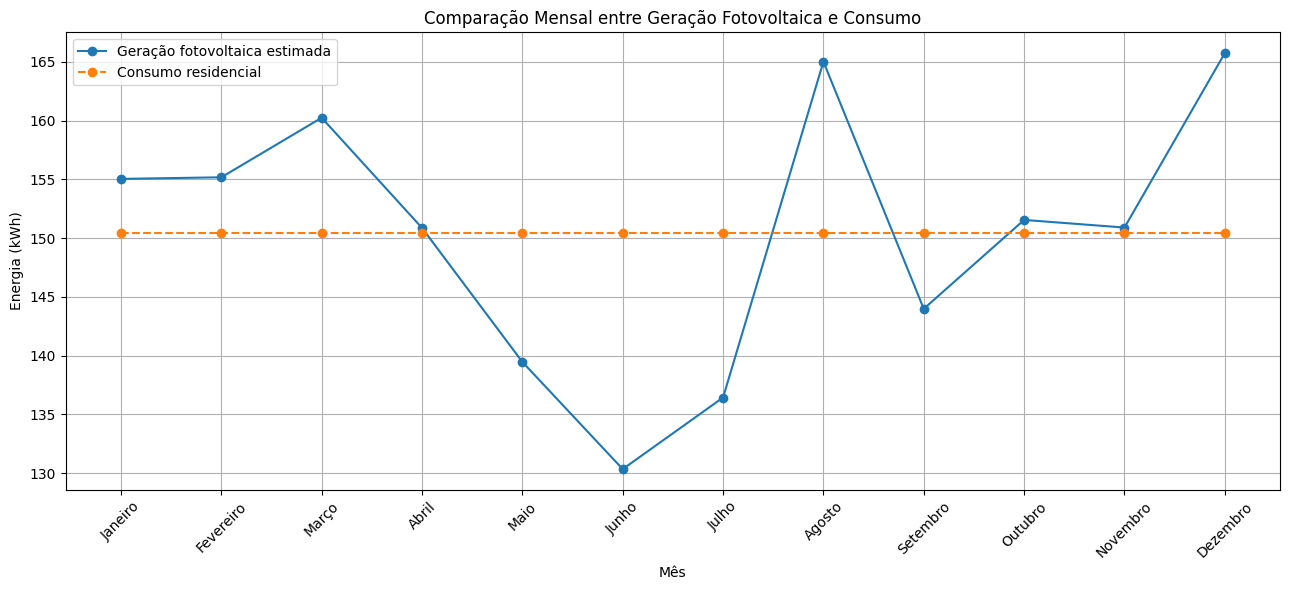

In [139]:

plt.figure(figsize=(13, 6))

plt.plot(
    dados_mensais["mes"],
    dados_mensais["geracao_sistema_kwh"],
    marker="o",
    label="Geração fotovoltaica estimada"
)

plt.plot(
    dados_mensais["mes"],
    dados_mensais["consumo_residencial_kwh"],
    marker="o",
    linestyle="--",
    label="Consumo residencial"
)

plt.title("Comparação Mensal entre Geração Fotovoltaica e Consumo")
plt.xlabel("Mês")
plt.ylabel("Energia (kWh)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


### Indicadores de Desempenho:

In [140]:

meses_com_deficit = dados_mensais[
    dados_mensais["saldo_energetico_kwh"] < 0
]

meses_com_excedente = dados_mensais[
    dados_mensais["saldo_energetico_kwh"] > 0
]

maior_deficit = dados_mensais.loc[
    dados_mensais["saldo_energetico_kwh"].idxmin()
]

maior_excedente = dados_mensais.loc[
    dados_mensais["saldo_energetico_kwh"].idxmax()
]

print("INDICADORES DE DESEMPENHO ENERGÉTICO")
print("-" * 55)

print(f"Meses com déficit: {len(meses_com_deficit)}")
print(f"Meses com excedente: {len(meses_com_excedente)}")

print(
    f"\nMaior déficit: {maior_deficit['mes']} "
    f"({maior_deficit['saldo_energetico_kwh']:.2f} kWh)"
)

print(
    f"Maior excedente: {maior_excedente['mes']} "
    f"({maior_excedente['saldo_energetico_kwh']:.2f} kWh)"
)

print(
    f"\nSaldo energético anual: "
    f"{dados_mensais['saldo_energetico_kwh'].sum():.2f} kWh"
)


INDICADORES DE DESEMPENHO ENERGÉTICO
-------------------------------------------------------
Meses com déficit: 4
Meses com excedente: 8

Maior déficit: Junho (-20.05 kWh)
Maior excedente: Dezembro (15.35 kWh)

Saldo energético anual: -0.00 kWh



### 10.1 Interpretação dos Resultados

A estimativa preliminar indicou uma potência fotovoltaica de aproximadamente 1,33 kWp para compensar o consumo anual de 1.804,80 kWh da residência hipotética.

Entretanto, a comparação mensal demonstrou que a geração não permanece constante ao longo do ano.

Foram identificados períodos de déficit energético, principalmente entre maio e julho, além de setembro. Em contrapartida, outros meses apresentam excedentes de geração, com destaque para agosto e dezembro.

Esses resultados demonstram que o dimensionamento baseado exclusivamente no consumo anual não representa, por si só, autossuficiência energética mensal.

A estimativa ainda possui limitações: utiliza um Performance Ratio hipotético, dados climatológicos de uma grade espacial e não considera características específicas de uma instalação real.

Portanto, os valores obtidos devem ser interpretados como uma referência inicial para comparação de alternativas energéticas, e não como um projeto executivo de instalação fotovoltaica.



### 10.2 Indicadores de Desempenho Energético

A comparação entre geração e consumo identificou quatro meses com déficit energético e oito meses com excedente.

O maior déficit foi observado em junho, com aproximadamente 20,05 kWh, enquanto o maior excedente ocorreu em dezembro, com aproximadamente 15,35 kWh.

O saldo energético anual ficou próximo de zero, resultado esperado devido ao dimensionamento baseado no consumo anual da residência.

Apesar desse equilíbrio anual, a distribuição mensal da geração demonstra que o sistema não atenderia integralmente à demanda em todos os períodos sem considerar a compensação de créditos energéticos ou o fornecimento complementar pela rede elétrica.

Os resultados reforçam a importância de avaliar não apenas a geração anual, mas também sua distribuição ao longo dos meses.


In [141]:

# Exportação dos resultados da análise fotovoltaica

# Organização dos dados mensais
colunas_exportacao = [
    "mes",
    "irradiacao_kwh_m2_dia",
    "dias_mes",
    "geracao_1kwp_kwh",
    "geracao_sistema_kwh",
    "consumo_residencial_kwh",
    "saldo_energetico_kwh"
]

df_resultado_solar = dados_mensais[colunas_exportacao].copy()

# Exportação da tabela mensal
arquivo_csv_solar = "resultado_geracao_fotovoltaica.csv"

df_resultado_solar.to_csv(
    arquivo_csv_solar,
    index=False,
    encoding="utf-8-sig"
)

# Organização dos indicadores gerais
resumo_solar = {
    "localidade": f"{cidade} - {estado}, {pais}",
    "origem_dados": "Atlas Brasileiro de Energia Solar - INPE/LABREN, 2ª edição",
    "ano_referencia_atlas": 2017,
    "perfil_residencial": {
        "moradores": quantidade_moradores,
        "consumo_mensal_kwh": round(consumo_mensal_kwh, 2),
        "consumo_anual_kwh": round(consumo_anual_kwh, 2)
    },
    "parametros_fotovoltaicos": {
        "performance_ratio": performance_ratio,
        "potencia_referencia_kwp": potencia_referencia_kwp,
        "potencia_estimada_kwp": round(potencia_estimada_kwp, 3),
        "geracao_anual_por_kwp_kwh": round(geracao_anual_1kwp, 2)
    },
    "indicadores": {
        "meses_com_deficit": int(len(meses_com_deficit)),
        "meses_com_excedente": int(len(meses_com_excedente)),
        "maior_deficit_mes": maior_deficit["mes"],
        "maior_deficit_kwh": round(
            float(maior_deficit["saldo_energetico_kwh"]), 2
        ),
        "maior_excedente_mes": maior_excedente["mes"],
        "maior_excedente_kwh": round(
            float(maior_excedente["saldo_energetico_kwh"]), 2
        )
    },
    "observacao": (
        "Estimativa preliminar baseada em dados climatológicos "
        "e premissas simplificadas. Não representa garantia de "
        "geração, economia financeira ou projeto executivo."
    )
}

arquivo_json_solar = "resumo_potencial_solar.json"

with open(arquivo_json_solar, "w", encoding="utf-8") as arquivo:
    json.dump(
        resumo_solar,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

print("RESULTADOS EXPORTADOS")
print("-" * 45)
print(f"Tabela mensal: {arquivo_csv_solar}")
print(f"Resumo geral: {arquivo_json_solar}")


RESULTADOS EXPORTADOS
---------------------------------------------
Tabela mensal: resultado_geracao_fotovoltaica.csv
Resumo geral: resumo_potencial_solar.json



## 11. Análise de Sensibilidade do Performance Ratio

O dimensionamento fotovoltaico realizado anteriormente utilizou um Performance Ratio (PR) de 0,80 como hipótese inicial.

Nesta etapa, será avaliada a influência desse parâmetro sobre a geração anual estimada e a potência necessária para atender ao consumo residencial.

Serão analisados três cenários:

- PR de 0,75;
- PR de 0,80;
- PR de 0,85.

Os valores representam cenários hipotéticos de desempenho utilizados para avaliar a sensibilidade do modelo. Não constituem medições de uma instalação real nem garantias de desempenho.

O objetivo é verificar como alterações nas perdas e no desempenho global do sistema podem modificar os resultados do dimensionamento preliminar.


In [142]:

# Análise de sensibilidade do Performance Ratio

cenarios_pr = [0.75, 0.80, 0.85]

resultados_sensibilidade = []

for pr in cenarios_pr:

    geracao_mensal_1kwp = (
        dados_mensais["irradiacao_kwh_m2_dia"]
        * dados_mensais["dias_mes"]
        * potencia_referencia_kwp
        * pr
    )

    geracao_anual = geracao_mensal_1kwp.sum()

    potencia_necessaria = (
        consumo_anual_kwh / geracao_anual
    )

    resultados_sensibilidade.append({
        "performance_ratio": pr,
        "geracao_anual_1kwp_kwh": geracao_anual,
        "potencia_estimada_kwp": potencia_necessaria
    })

df_sensibilidade = pd.DataFrame(resultados_sensibilidade)

print("ANÁLISE DE SENSIBILIDADE DO PERFORMANCE RATIO")
print("-" * 65)

display(
    df_sensibilidade.round(3)
)


ANÁLISE DE SENSIBILIDADE DO PERFORMANCE RATIO
-----------------------------------------------------------------


,performance_ratio,geracao_anual_1kwp_kwh,potencia_estimada_kwp
0,0.75,1274.19,1.42
1,0.80,1359.14,1.33
2,0.85,1444.09,1.25



### 11.1 Interpretação dos Resultados

Os resultados demonstram que o Performance Ratio influencia diretamente a estimativa de geração fotovoltaica e a potência necessária para atender ao consumo residencial.

No cenário com PR de 0,75, a geração estimada por kWp é menor, exigindo aproximadamente 1,42 kWp de potência instalada.

No cenário de referência, com PR de 0,80, a potência estimada é de aproximadamente 1,33 kWp.

Já no cenário com PR de 0,85, a geração estimada aumenta, reduzindo a potência necessária para aproximadamente 1,25 kWp.

A diferença entre os cenários evidencia que o dimensionamento depende das condições de desempenho consideradas no modelo.

Portanto, o valor de 0,80 foi mantido como referência para as análises anteriores, mas os resultados devem ser interpretados considerando a possibilidade de variação do desempenho real da instalação.



## 12. Premissas e Limitações da Estimativa Fotovoltaica

A estimativa de geração fotovoltaica utiliza dados climatológicos do Atlas Brasileiro de Energia Solar e um modelo simplificado de conversão da irradiação em energia elétrica.

Os resultados devem ser interpretados considerando as seguintes premissas:

1. **Dados climatológicos:** os valores de irradiação representam médias históricas, não previsões meteorológicas ou medições de uma instalação específica.

2. **Referência geográfica:** foi utilizado o ponto de grade mais próximo de uma coordenada aproximada da região central de São Paulo. Esse ponto não representa necessariamente as condições de um imóvel específico.

3. **Performance Ratio:** foi adotado um PR de 0,80 como hipótese de referência. A análise de sensibilidade demonstrou como alterações nesse parâmetro influenciam a geração estimada e a potência necessária.

4. **Características da instalação:** não foram avaliados individualmente o sombreamento, a orientação real dos módulos, as condições estruturais do telhado ou as características dos equipamentos.

5. **Consumo residencial:** o consumo mensal foi considerado constante durante os doze meses, embora o comportamento real de uma residência possa variar.

6. **Balanço energético:** a comparação entre geração e consumo representa uma estimativa de energia. Ela não determina diretamente o valor final da fatura ou a compensação financeira da energia excedente.

7. **Dimensionamento:** a potência calculada representa uma referência energética preliminar, não um projeto executivo ou uma especificação definitiva de equipamentos.

Dessa forma, os resultados permitem avaliar o potencial da geração fotovoltaica no cenário residencial estudado, mas não garantem geração, economia financeira ou viabilidade de instalação.



## 13. Referências Utilizadas

### Dados de irradiação solar

PEREIRA, Enio Bueno et al. **Atlas Brasileiro de Energia Solar**. 2. ed. São José dos Campos: INPE, 2017.

Instituto Nacional de Pesquisas Espaciais (INPE) — Laboratório de Modelagem e Estudos de Recursos Renováveis de Energia (LABREN).

- Página oficial do Atlas: https://labren.ccst.inpe.br/atlas_2017.html
- Tabela de irradiação no plano inclinado para o estado de São Paulo: https://labren.ccst.inpe.br/atlas2_tables/SP_inc-en.html

### Premissas do modelo

- Performance Ratio de referência: 0,80, adotado como hipótese metodológica para a estimativa.
- Cenários de sensibilidade: PR de 0,75, 0,80 e 0,85.
- Consumo residencial: 150,40 kWh/mês, obtido da análise desenvolvida no Notebook 01.
- Coordenada geográfica: referência aproximada da região central de São Paulo, utilizada para selecionar o ponto de irradiação mais próximo.

Os resultados apresentados neste notebook foram calculados a partir dos dados e das premissas descritos acima. As estimativas não representam medições de uma instalação fotovoltaica real.



### Referências complementares — Impactos ambientais

INTERNATIONAL RENEWABLE ENERGY AGENCY (IRENA);
INTERNATIONAL ENERGY AGENCY PHOTOVOLTAIC POWER
SYSTEMS PROGRAMME (IEA-PVPS).

**End-of-Life Management: Solar Photovoltaic Panels.**
2016.

Disponível em:
https://www.irena.org/publications/2016/Jun/End-of-life-management-Solar-Photovoltaic-Panels

Esta publicação aborda a gestão de módulos
fotovoltaicos ao final da vida útil, incluindo
questões relacionadas aos materiais e resíduos.

INTERGOVERNMENTAL PANEL ON CLIMATE CHANGE (IPCC).

**Climate Change 2022: Mitigation of Climate Change.**
Contribution of Working Group III to the Sixth
Assessment Report. Cambridge University Press, 2022.

Disponível em:
https://www.ipcc.ch/report/ar6/wg3/

O relatório fornece fundamentação sobre mitigação
das mudanças climáticas, sistemas energéticos,
fontes de baixo carbono e eficiência energética.

Essas referências são utilizadas para fundamentar
a discussão qualitativa dos impactos ambientais.
O presente projeto não realizou uma análise própria
de ciclo de vida ou quantificação de emissões evitadas.


In [143]:

# Exportação dos resultados da análise fotovoltaica

# Organização dos resultados mensais
colunas_exportacao = [
    "mes",
    "irradiacao_kwh_m2_dia",
    "dias_mes",
    "geracao_1kwp_kwh",
    "geracao_sistema_kwh",
    "consumo_residencial_kwh",
    "saldo_energetico_kwh"
]

df_resultado_solar = dados_mensais[colunas_exportacao].copy()

# Exportação dos dados mensais
arquivo_csv = "resultado_geracao_fotovoltaica.csv"

df_resultado_solar.to_csv(
    arquivo_csv,
    index=False,
    encoding="utf-8-sig"
)

# Exportação da análise de sensibilidade
arquivo_sensibilidade = "sensibilidade_performance_ratio.csv"

df_sensibilidade.to_csv(
    arquivo_sensibilidade,
    index=False,
    encoding="utf-8-sig"
)

# Organização do resumo geral
resumo_solar = {
    "localidade": f"{cidade} - {estado}, {pais}",
    "fonte_dados": "Atlas Brasileiro de Energia Solar - INPE/LABREN",
    "edicao_atlas": "2ª edição, 2017",
    "ponto_referencia": {
        "id": int(ponto_irradiacao["ID"]),
        "latitude": float(ponto_irradiacao["LAT"]),
        "longitude": float(ponto_irradiacao["LON"]),
        "distancia_referencia_km": round(
            float(ponto_irradiacao["distancia_km"]), 2
        )
    },
    "consumo_residencial": {
        "moradores": int(quantidade_moradores),
        "consumo_mensal_kwh": round(float(consumo_mensal_kwh), 2),
        "consumo_anual_kwh": round(float(consumo_anual_kwh), 2)
    },
    "parametros_fotovoltaicos": {
        "performance_ratio_referencia": float(performance_ratio),
        "potencia_referencia_kwp": float(potencia_referencia_kwp),
        "potencia_estimada_kwp": round(
            float(potencia_estimada_kwp), 3
        ),
        "geracao_anual_por_kwp_kwh": round(
            float(geracao_anual_1kwp), 2
        )
    },
    "sensibilidade_performance_ratio": [
        {
            "performance_ratio": float(linha["performance_ratio"]),
            "geracao_anual_1kwp_kwh": round(
                float(linha["geracao_anual_1kwp_kwh"]), 2
            ),
            "potencia_estimada_kwp": round(
                float(linha["potencia_estimada_kwp"]), 3
            )
        }
        for _, linha in df_sensibilidade.iterrows()
    ],
    "limitacao": (
        "Estimativa preliminar baseada em médias climatológicas "
        "e premissas simplificadas. Não representa garantia de "
        "geração, economia financeira ou projeto executivo."
    )
}

# Exportação do resumo em JSON
arquivo_json = "resumo_potencial_solar.json"

with open(arquivo_json, "w", encoding="utf-8") as arquivo:
    json.dump(
        resumo_solar,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

print("EXPORTAÇÃO CONCLUÍDA")
print("-" * 45)
print(f"Resultados mensais: {arquivo_csv}")
print(f"Análise de sensibilidade: {arquivo_sensibilidade}")
print(f"Resumo geral: {arquivo_json}")


EXPORTAÇÃO CONCLUÍDA
---------------------------------------------
Resultados mensais: resultado_geracao_fotovoltaica.csv
Análise de sensibilidade: sensibilidade_performance_ratio.csv
Resumo geral: resumo_potencial_solar.json



## 14. Alternativa de Eficiência Energética — Redução do Consumo do Chuveiro

Além da geração fotovoltaica, será analisada uma alternativa baseada na redução do consumo de energia elétrica.

O equipamento selecionado é o chuveiro elétrico, cuja estimativa de consumo foi desenvolvida no Notebook 01.

A proposta consiste em reduzir em 20% o tempo total diário de utilização do chuveiro na residência, mantendo a potência do equipamento e os demais parâmetros constantes.

O objetivo é estimar a economia de energia mensal e anual obtida por essa mudança de hábito.

**Premissa:** a redução de 20% representa um cenário hipotético de simulação. A economia efetiva dependerá do comportamento dos moradores e das condições reais de utilização.


### Procedimento de economia de energia com o chuveiro elétrico

O chuveiro elétrico representa uma parcela significativa do consumo
estimado da residência. Por esse motivo, a redução do tempo de
funcionamento foi escolhida como medida de eficiência energética.

Para demonstrar o potencial dessa medida, foi considerado um cenário
hipotético de redução de 20% no tempo diário de utilização do chuveiro.

Na prática, essa medida pode ser adotada por meio das seguintes ações:

1. **Planejamento do banho:** organizar previamente os itens necessários
   para evitar que o chuveiro permaneça ligado enquanto o usuário
   realiza outras atividades.

2. **Controle do tempo:** acompanhar a duração dos banhos e estabelecer
   uma meta de redução gradual, respeitando as necessidades dos moradores.

3. **Uso consciente da água:** evitar manter o chuveiro funcionando
   durante momentos em que a água não esteja sendo utilizada, desde
   que isso possa ser feito com segurança e conforto.

4. **Acompanhamento do consumo:** observar periodicamente o tempo total
   de funcionamento do chuveiro na residência e comparar os resultados
   com a estimativa inicial.

No cenário utilizado neste estudo, o tempo total diário de funcionamento
passa de 30 para 24 minutos, representando uma redução de 6 minutos
por dia.

A economia resultante é estimada em 16,50 kWh mensais e 198 kWh anuais.

É importante destacar que esses valores representam uma simulação.
A economia efetiva depende dos hábitos dos moradores, da potência
real do equipamento e das condições de utilização.

Não é necessário modificar a instalação elétrica ou abrir o equipamento
para aplicar essa medida de eficiência energética.

In [144]:

# Parâmetros do chuveiro elétrico definidos no Notebook 01

potencia_chuveiro_kw = 5.5
horas_uso_diario_chuveiro = 0.5
dias_uso_mes_chuveiro = 30

# Consumo original estimado
consumo_chuveiro_original_kwh = (
    potencia_chuveiro_kw
    * horas_uso_diario_chuveiro
    * dias_uso_mes_chuveiro
)

# Cenário hipotético: redução de 20% no tempo de utilização
percentual_reducao_chuveiro = 0.20

horas_uso_diario_reduzido = (
    horas_uso_diario_chuveiro
    * (1 - percentual_reducao_chuveiro)
)

# Consumo após a redução
consumo_chuveiro_reduzido_kwh = (
    potencia_chuveiro_kw
    * horas_uso_diario_reduzido
    * dias_uso_mes_chuveiro
)

# Economia estimada
economia_mensal_eficiencia_kwh = (
    consumo_chuveiro_original_kwh
    - consumo_chuveiro_reduzido_kwh
)

economia_anual_eficiencia_kwh = (
    economia_mensal_eficiencia_kwh * 12
)

# Novo consumo residencial estimado
consumo_residencial_eficiencia_mensal_kwh = (
    consumo_mensal_kwh
    - economia_mensal_eficiencia_kwh
)

consumo_residencial_eficiencia_anual_kwh = (
    consumo_residencial_eficiencia_mensal_kwh * 12
)

# Organização dos resultados
resultado_eficiencia = pd.DataFrame([
    {
        "indicador": "Consumo original do chuveiro",
        "mensal_kwh": consumo_chuveiro_original_kwh,
        "anual_kwh": consumo_chuveiro_original_kwh * 12
    },
    {
        "indicador": "Consumo reduzido do chuveiro",
        "mensal_kwh": consumo_chuveiro_reduzido_kwh,
        "anual_kwh": consumo_chuveiro_reduzido_kwh * 12
    },
    {
        "indicador": "Economia estimada",
        "mensal_kwh": economia_mensal_eficiencia_kwh,
        "anual_kwh": economia_anual_eficiencia_kwh
    },
    {
        "indicador": "Consumo residencial após redução",
        "mensal_kwh": consumo_residencial_eficiencia_mensal_kwh,
        "anual_kwh": consumo_residencial_eficiencia_anual_kwh
    }
])

print("ANÁLISE DE EFICIÊNCIA ENERGÉTICA")
print("-" * 55)
print(f"Redução no tempo de uso: {percentual_reducao_chuveiro:.0%}")
print(
    f"Tempo diário original: "
    f"{horas_uso_diario_chuveiro * 60:.1f} minutos"
)
print(
    f"Tempo diário reduzido: "
    f"{horas_uso_diario_reduzido * 60:.1f} minutos"
)

display(resultado_eficiencia.round(2))


ANÁLISE DE EFICIÊNCIA ENERGÉTICA
-------------------------------------------------------
Redução no tempo de uso: 20%
Tempo diário original: 30.0 minutos
Tempo diário reduzido: 24.0 minutos


,indicador,mensal_kwh,anual_kwh
0,Consumo original do chuveiro,82.50,990.00
1,Consumo reduzido do chuveiro,66.00,792.00
2,Economia estimada,16.50,198.00
3,Consumo residencial após redução,133.90,1606.80



## 15. Comparação das Alternativas Energéticas

Esta seção compara duas alternativas aplicáveis ao cenário residencial analisado:

1. **Geração fotovoltaica:** instalação de um sistema solar com potência estimada para atender ao consumo anual de referência da residência.
2. **Eficiência energética:** redução de 20% no tempo de utilização do chuveiro elétrico, diminuindo a demanda de energia da residência.

A comparação considera os resultados anuais estimados, os custos conhecidos, a viabilidade de aplicação e os impactos ambientais.

É importante distinguir a energia potencialmente gerada pelo sistema fotovoltaico da energia efetivamente economizada pela mudança de hábito. A geração solar depende das condições de instalação e operação, enquanto a economia por eficiência depende da adesão dos moradores.

O custo de aquisição e instalação do sistema fotovoltaico ainda não foi definido por orçamento. Por esse motivo, não será estimado um prazo de retorno financeiro nesta etapa.


In [145]:

# Tarifa de referência obtida no Notebook 01
tarifa_referencia_kwh = 0.78938

# Resultado anual estimado da geração fotovoltaica
geracao_fotovoltaica_anual_kwh = dados_mensais[
    "geracao_sistema_kwh"
].sum()

# Resultado anual estimado da eficiência energética
economia_eficiencia_anual_kwh = economia_anual_eficiencia_kwh

# Estimativa financeira da economia por eficiência
economia_financeira_eficiencia_anual = (
    economia_eficiencia_anual_kwh * tarifa_referencia_kwh
)

economia_financeira_eficiencia_mensal = (
    economia_financeira_eficiencia_anual / 12
)

# Tabela comparativa
comparacao_alternativas = pd.DataFrame([
    {
        "alternativa": "Geração fotovoltaica",
        "resultado_anual_kwh": geracao_fotovoltaica_anual_kwh,
        "potencia_kwp": potencia_estimada_kwp,
        "beneficio_financeiro_anual": None,
        "custo_inicial": "Não definido"
    },
    {
        "alternativa": "Eficiência energética",
        "resultado_anual_kwh": economia_eficiencia_anual_kwh,
        "potencia_kwp": None,
        "beneficio_financeiro_anual": economia_financeira_eficiencia_anual,
        "custo_inicial": "Sem aquisição de equipamentos no cenário simulado"
    }
])

print("COMPARAÇÃO QUANTITATIVA DAS ALTERNATIVAS")
print("-" * 65)

display(comparacao_alternativas.round(2))

print("\nECONOMIA FINANCEIRA ESTIMADA POR EFICIÊNCIA")
print(
    f"Mensal: R$ {economia_financeira_eficiencia_mensal:.2f}"
)
print(
    f"Anual: R$ {economia_financeira_eficiencia_anual:.2f}"
)


COMPARAÇÃO QUANTITATIVA DAS ALTERNATIVAS
-----------------------------------------------------------------


,alternativa,resultado_anual_kwh,potencia_kwp,beneficio_financeiro_anual,custo_inicial
0,Geração fotovoltaica,1804.80,1.33,NaN,Não definido
1,Eficiência energética,198.00,NaN,156.30,Sem aquisição de equipamentos no cenário simulado



ECONOMIA FINANCEIRA ESTIMADA POR EFICIÊNCIA
Mensal: R$ 13.02
Anual: R$ 156.30



### 15.3. Viabilidade Econômica e Impactos Ambientais

A comparação considera as condições de implementação,
os custos identificados e os impactos ambientais das
duas alternativas propostas.

#### Alternativa 1 — Geração fotovoltaica

**Viabilidade técnica:**

A instalação depende da área disponível, orientação,
inclinação e sombreamento do telhado, além das condições
estruturais do imóvel e das exigências de conexão à rede.

A potência estimada de aproximadamente 1,328 kWp
representa um dimensionamento energético preliminar,
não um projeto executivo.

**Viabilidade econômica:**

A instalação exige investimento em módulos fotovoltaicos,
inversor, estruturas de fixação, materiais elétricos e
serviços especializados.

O estudo não dispõe de orçamento real para esses componentes.
O custo foi estimado no Notebook 03 (seção 2.5) com preços
médios de mercado (R$ 2,45 a R$ 2,84 por Wp): de R$ 3,3 mil
a R$ 3,8 mil para 1,33 kWp, como piso de referência.

A geração anual estimada de 1.804,80 kWh não pode ser
convertida diretamente em economia financeira garantida,
pois o faturamento depende das condições de consumo,
compensação energética e regras tarifárias aplicáveis.

**Impactos ambientais:**

A geração fotovoltaica utiliza energia solar, uma fonte
renovável, e não depende da queima de combustíveis durante
a produção direta de eletricidade.

Entretanto, a fabricação dos módulos, a obtenção de
matérias-primas, o transporte, a instalação e o tratamento
dos equipamentos ao final da vida útil apresentam
impactos ambientais que devem ser considerados em uma
avaliação de ciclo de vida.

As emissões evitadas foram estimadas no Notebook 03
(seção 2.5) com o fator médio do SIN em 2025 (MCTI):
cerca de 83 kg de CO2 por ano. A análise de ciclo de
vida dos equipamentos não foi feita.

#### Alternativa 2 — Eficiência energética

**Viabilidade técnica:**

A redução de 20% no tempo total de funcionamento do
chuveiro elétrico pode ser aplicada por mudança de
hábitos, sem modificações na instalação elétrica.

A implementação depende da participação dos moradores
e deve preservar condições adequadas de higiene,
conforto e segurança.

**Viabilidade econômica:**

No cenário simulado, não é necessário adquirir
equipamentos adicionais.

A economia estimada é de 16,50 kWh por mês, ou
198 kWh por ano.

Utilizando a tarifa de referência de R$ 0,78938/kWh,
a economia financeira estimada corresponde a
aproximadamente R$ 13,02 mensais e R$ 156,30 anuais.

Esses valores não representam uma redução garantida
da fatura, pois dependem do comportamento dos moradores
e das condições tarifárias efetivas.

**Impactos ambientais:**

A redução do consumo diminui a demanda de eletricidade
necessária para atender à residência.

Os benefícios ambientais associados dependem das
características do sistema elétrico que fornece energia.

Com o fator médio do SIN em 2025, a economia de 198 kWh
por ano evita cerca de 9 kg de CO2 (Notebook 03, seção 2.5).

#### Comparação e limitações

A geração fotovoltaica apresenta maior contribuição
energética anual estimada, mas exige investimento
financeiro, avaliação técnica e condições físicas
adequadas para instalação.

A eficiência energética apresenta menor barreira
inicial de implementação no cenário estudado, mas
depende da manutenção dos hábitos dos moradores.

As alternativas são complementares: reduzir o consumo
pode diminuir a potência necessária de um sistema
fotovoltaico futuro.

Os resultados econômicos e ambientais apresentados
possuem limitações distintas e não devem ser
interpretados como garantias de desempenho,
economia financeira ou redução de emissões.



### 15.4. Interpretação dos Resultados

A comparação demonstra que as duas alternativas contribuem de maneiras diferentes para a sustentabilidade energética residencial.

A geração fotovoltaica apresenta potencial estimado de 1.804,80 kWh anuais, equivalente ao consumo anual de referência da residência. Entretanto, sua implementação depende de investimento inicial, condições físicas adequadas e avaliação técnica do imóvel.

A alternativa de eficiência energética apresenta uma economia estimada de 198 kWh anuais, considerando a redução de 20% no tempo de utilização do chuveiro elétrico. Essa medida não exige investimento em equipamentos no cenário analisado e pode ser aplicada por meio da mudança de hábitos dos moradores.

Embora a geração fotovoltaica apresente um resultado energético anual maior, a eficiência energética possui menor barreira inicial de implementação.

Portanto, as alternativas não são necessariamente excludentes. A redução do consumo pode ser aplicada independentemente da instalação fotovoltaica, contribuindo para diminuir a demanda energética da residência e potencialmente reduzir a capacidade necessária de um futuro sistema de geração.

Os resultados devem ser interpretados como estimativas baseadas nas premissas adotadas, e não como garantias de economia financeira ou geração efetiva.



### 15.5. Efeito da Eficiência Energética no Dimensionamento Fotovoltaico

Além dos benefícios individuais, as duas alternativas podem atuar de maneira complementar.

A redução do consumo residencial diminui a quantidade anual de energia que precisaria ser gerada por um sistema fotovoltaico para compensar energeticamente a demanda da residência.

Nesta análise, será estimada a potência fotovoltaica necessária antes e depois da aplicação da medida de eficiência energética, mantendo a mesma geração anual de referência por kWp.

O objetivo é demonstrar o efeito potencial da redução do consumo sobre o dimensionamento energético do sistema solar.

Os resultados são estimativas teóricas e não substituem um projeto fotovoltaico dimensionado por profissional habilitado.


In [146]:

# Dimensionamento original
potencia_fotovoltaica_original_kwp = (
    consumo_anual_kwh / geracao_anual_1kwp
)

# Dimensionamento após a medida de eficiência energética
potencia_fotovoltaica_reduzida_kwp = (
    consumo_residencial_eficiencia_anual_kwh
    / geracao_anual_1kwp
)

# Diferença entre os dimensionamentos
reducao_potencia_kwp = (
    potencia_fotovoltaica_original_kwp
    - potencia_fotovoltaica_reduzida_kwp
)

percentual_reducao_potencia = (
    reducao_potencia_kwp
    / potencia_fotovoltaica_original_kwp
) * 100

# Tabela comparativa
comparacao_dimensionamento = pd.DataFrame([
    {
        "cenario": "Consumo residencial original",
        "consumo_anual_kwh": consumo_anual_kwh,
        "potencia_estimada_kwp": potencia_fotovoltaica_original_kwp
    },
    {
        "cenario": "Após eficiência energética",
        "consumo_anual_kwh": consumo_residencial_eficiencia_anual_kwh,
        "potencia_estimada_kwp": potencia_fotovoltaica_reduzida_kwp
    }
])

print("EFEITO DA EFICIÊNCIA NO DIMENSIONAMENTO FOTOVOLTAICO")
print("-" * 65)

display(comparacao_dimensionamento.round(3))

print(
    f"\nRedução teórica da potência necessária: "
    f"{reducao_potencia_kwp:.3f} kWp"
)

print(
    f"Redução percentual estimada: "
    f"{percentual_reducao_potencia:.2f}%"
)


EFEITO DA EFICIÊNCIA NO DIMENSIONAMENTO FOTOVOLTAICO
-----------------------------------------------------------------


,cenario,consumo_anual_kwh,potencia_estimada_kwp
0,Consumo residencial original,1804.80,1.33
1,Após eficiência energética,1606.80,1.18



Redução teórica da potência necessária: 0.146 kWp
Redução percentual estimada: 10.97%



## 16. Integração ao Citizen Assist AI

Os resultados da análise energética serão organizados em uma base de conhecimento para apoiar as respostas do Citizen Assist AI.

O objetivo é permitir que o assistente apresente orientações fundamentadas nas duas alternativas analisadas:

- Geração de energia solar fotovoltaica.
- Eficiência energética por redução do tempo de utilização do chuveiro elétrico.

As orientações deverão apresentar os resultados estimados, explicar as condições de aplicação e informar as limitações de cada alternativa.

Os valores utilizados nesta seção são provenientes das análises realizadas nos Notebooks 01 e 02.


In [147]:

# Base de conhecimento energética do Citizen Assist AI

base_conhecimento_energia = {
    "publico": {
        "descricao": "Residência hipotética com quatro moradores",
        "localizacao_referencia": "São Paulo - SP",
        "consumo_mensal_kwh": consumo_mensal_kwh,
        "consumo_anual_kwh": consumo_mensal_kwh * 12,
        "tarifa_referencia_kwh": tarifa_referencia_kwh
    },

    "dimensionamento_combinado": {
        "potencia_original_kwp": potencia_fotovoltaica_original_kwp,
        "potencia_apos_eficiencia_kwp": potencia_fotovoltaica_reduzida_kwp,
        "reducao_potencia_kwp": reducao_potencia_kwp,
        "reducao_percentual": percentual_reducao_potencia
    },


    "energia_fotovoltaica": {
        "potencia_estimada_kwp": potencia_estimada_kwp,
        "geracao_anual_estimada_kwh": geracao_fotovoltaica_anual_kwh,
        "performance_ratio": performance_ratio,
        "custo_inicial": "Não definido por ausência de orçamento",
        "limitacoes": [
            "Depende das condições de instalação do imóvel",
            "Depende da orientação, inclinação e sombreamento",
            "A geração estimada não representa redução garantida na fatura",
            "Exige avaliação técnica e orçamento especializado"
        ]
    },

    "eficiencia_energetica": {
        "equipamento": "Chuveiro elétrico",
        "reducao_percentual": percentual_reducao_chuveiro * 100,
        "economia_mensal_kwh": economia_mensal_eficiencia_kwh,
        "economia_anual_kwh": economia_eficiencia_anual_kwh,
        "economia_financeira_anual": economia_financeira_eficiencia_anual,
        "limitacoes": [
            "A redução depende da mudança de hábito dos moradores",
            "O percentual de economia é um cenário hipotético",
            "O valor financeiro utiliza uma tarifa de referência"
        ]
    }
}

print("BASE DE CONHECIMENTO ENERGÉTICA")
print("-" * 50)

print("Público:", base_conhecimento_energia["publico"]["descricao"])
print(
    "Consumo mensal:",
    f'{base_conhecimento_energia["publico"]["consumo_mensal_kwh"]:.2f} kWh'
)

print("\nALTERNATIVA FOTOVOLTAICA")
print(
    "Potência estimada:",
    f'{base_conhecimento_energia["energia_fotovoltaica"]["potencia_estimada_kwp"]:.2f} kWp'
)
print(
    "Geração anual:",
    f'{base_conhecimento_energia["energia_fotovoltaica"]["geracao_anual_estimada_kwh"]:.2f} kWh'
)

print("\nALTERNATIVA DE EFICIÊNCIA ENERGÉTICA")
print(
    "Economia anual:",
    f'{base_conhecimento_energia["eficiencia_energetica"]["economia_anual_kwh"]:.2f} kWh'
)
print(
    "Economia financeira estimada:",
    f'R$ {base_conhecimento_energia["eficiencia_energetica"]["economia_financeira_anual"]:.2f}'
)


BASE DE CONHECIMENTO ENERGÉTICA
--------------------------------------------------
Público: Residência hipotética com quatro moradores
Consumo mensal: 150.40 kWh

ALTERNATIVA FOTOVOLTAICA
Potência estimada: 1.33 kWp
Geração anual: 1804.80 kWh

ALTERNATIVA DE EFICIÊNCIA ENERGÉTICA
Economia anual: 198.00 kWh
Economia financeira estimada: R$ 156.30



### 16.3. Demonstração de Orientação ao Cidadão

A partir dos dados estruturados, o Citizen Assist AI poderá apresentar recomendações contextualizadas para moradores interessados em reduzir o consumo de energia elétrica.

A resposta demonstrativa a seguir utiliza os resultados calculados neste projeto. Ela não representa uma consulta a dados individuais de um consumidor.

COMBINAÇÃO DAS ALTERNATIVAS

A adoção de medidas de eficiência energética antes da instalação de um sistema fotovoltaico também pode reduzir a potência necessária para atender ao consumo residencial.

No cenário analisado, a redução estimada do consumo diminuiu a potência fotovoltaica de aproximadamente 1,33 kWp para 1,18 kWp, representando uma redução de cerca de 10,97% na potência necessária.

Essa combinação pode contribuir para um dimensionamento mais adequado do sistema, embora sua viabilidade dependa das condições específicas do imóvel.

In [148]:

# Demonstração de orientação energética do Citizen Assist AI

dados_publico = base_conhecimento_energia["publico"]
dados_solar = base_conhecimento_energia["energia_fotovoltaica"]
dados_eficiencia = base_conhecimento_energia["eficiencia_energetica"]
dados_combinados = base_conhecimento_energia["dimensionamento_combinado"]

resposta_citizen_assist = f"""
ORIENTAÇÃO ENERGÉTICA — CITIZEN ASSIST AI

Considerando o cenário residencial analisado, com consumo estimado
de {dados_publico["consumo_mensal_kwh"]:.2f} kWh por mês,
existem duas alternativas que podem contribuir para uma utilização
mais sustentável da energia elétrica.

1. ENERGIA SOLAR FOTOVOLTAICA

Um sistema com potência estimada de
{dados_solar["potencia_estimada_kwp"]:.2f} kWp poderia gerar aproximadamente
{dados_solar["geracao_anual_estimada_kwh"]:.2f} kWh por ano,
conforme as condições de referência utilizadas na simulação.

Antes da instalação, é necessário avaliar o imóvel, o telhado,
o sombreamento, os custos e as condições de conexão à rede elétrica.

2. EFICIÊNCIA ENERGÉTICA

Uma redução hipotética de {dados_eficiencia["reducao_percentual"]:.0f}%
no tempo de utilização do chuveiro elétrico representa uma economia
estimada de {dados_eficiencia["economia_mensal_kwh"]:.2f} kWh por mês,
ou {dados_eficiencia["economia_anual_kwh"]:.2f} kWh por ano.

Considerando a tarifa de referência adotada, isso corresponde
a uma economia financeira aproximada de
R$ {dados_eficiencia["economia_financeira_anual"]:.2f} por ano.

3. COMBINAÇÃO DAS ALTERNATIVAS

A adoção de medidas de eficiência energética antes da instalação
de um sistema fotovoltaico pode reduzir a potência necessária
para atender ao consumo residencial.

No cenário analisado, a potência estimada passa de
{dados_combinados["potencia_original_kwp"]:.3f} kWp para
{dados_combinados["potencia_apos_eficiencia_kwp"]:.3f} kWp,
representando uma redução aproximada de
{dados_combinados["reducao_percentual"]:.2f}% na potência necessária.

RECOMENDAÇÃO

A redução do tempo de utilização do chuveiro é uma medida que
pode ser adotada sem investimento em novos equipamentos no cenário
analisado.

A geração fotovoltaica pode ser considerada como uma alternativa
de fornecimento renovável, desde que exista viabilidade técnica
e financeira para sua instalação.

A combinação das duas alternativas pode contribuir para um
dimensionamento fotovoltaico mais adequado ao consumo da residência.

IMPORTANTE

Os valores apresentados são estimativas baseadas em um cenário
residencial hipotético. A geração, a economia financeira e os
resultados reais dependem das condições de cada residência.

O dimensionamento apresentado é uma referência energética
preliminar e não substitui uma avaliação técnica de instalação.
"""

print(resposta_citizen_assist)



ORIENTAÇÃO ENERGÉTICA — CITIZEN ASSIST AI

Considerando o cenário residencial analisado, com consumo estimado
de 150.40 kWh por mês,
existem duas alternativas que podem contribuir para uma utilização
mais sustentável da energia elétrica.

1. ENERGIA SOLAR FOTOVOLTAICA

Um sistema com potência estimada de
1.33 kWp poderia gerar aproximadamente
1804.80 kWh por ano,
conforme as condições de referência utilizadas na simulação.

Antes da instalação, é necessário avaliar o imóvel, o telhado,
o sombreamento, os custos e as condições de conexão à rede elétrica.

2. EFICIÊNCIA ENERGÉTICA

Uma redução hipotética de 20%
no tempo de utilização do chuveiro elétrico representa uma economia
estimada de 16.50 kWh por mês,
ou 198.00 kWh por ano.

Considerando a tarifa de referência adotada, isso corresponde
a uma economia financeira aproximada de
R$ 156.30 por ano.

3. COMBINAÇÃO DAS ALTERNATIVAS

A adoção de medidas de eficiência energética antes da instalação
de um sistema fotovoltaico pode reduzir 